In [1]:
from argparse import ArgumentParser, Namespace
import Spectral_Preprocessing as sp
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
parser = ArgumentParser()
parser.add_argument("--range-ir-1", dest= "wn_range_ir_1", default = (948,1860))
parser.add_argument("--range-ir-2", dest= "wn_range_ir_2", default = (2698,3002))

parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--finger-print-exl", dest= "finger_print_exl", type = bool, default = False)
parser.add_argument("--background-rule-ir", dest= "background_rule", type = str, default = 'mean')
parser.add_argument("--threshold-mean-intensity-ir", dest= "ths_mean_int_ir", type = float, default = 0)
parser.add_argument("--threshold-total-variation-intensity-ir", dest= "ths_tot_var_int_ir", type = float, default = 0)

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)


_StoreAction(option_strings=['--baseline'], dest='baseline', nargs=None, const=None, default=5, type=<class 'int'>, choices=None, required=False, help=None, metavar=None)

In [139]:
###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (980, 1800)
args.wn_range_ir_2 = (2720, 2970) #981.0,2969.0
args.range_min_ir = 675 ###enter an integer
args.range_max_ir = 4000 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 2 ###enter an integer
args.finger_print_exl = False
args.trans_chip = False
args.background_rule = 'none'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.60#0.4543

args.range_min_raman = 355.555542 ###enter an integer or float 
args.range_max_raman = 3500#3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.168021680216802 ###enter an integer or float

args.rubberband = 'specy' ###True for rubberband, False for iModPoly
args.minmax = 'snv' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = True ##True for calibration, False for no calibration.
args.si_peak = 520 ###enter an integer or float

#directory_name = '/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
directory_name = 'MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

In [165]:
spectra = pd.read_excel('gloves_contamination/Spectra_for_Matching.xlsx')
spectra = spectra.iloc[:,[0,1,4]]
spectra.columns = ['wavenumber','PE38','iN10 stearate']
spectra = spectra.set_index('wavenumber').T
spectra = spectra.iloc[:,143:-1]
#spectra = spectra.iloc[:,:-1]
spectra = 2-np.log(spectra/100)
spectra[spectra == np.inf] = None
idx_1 = np.where(np.isnan(spectra))[0]
idx_2 = np.where(np.isnan(spectra))[1]
#spectra.iloc[0,idx_2[idx_1==0]] = spectra.mean(1)[0]
#spectra.iloc[1,idx_2[idx_1==1]] = spectra.mean(1)[1]

spectra['polymer'] = ['PE38','iN10 stearate']
spectra['map_x'] = ''
spectra['map_y'] = ''
df_list = [[spectra.iloc[:1,:], spectra.iloc[:1,:]]]

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/pandas/core/internals/blocks.py:351: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


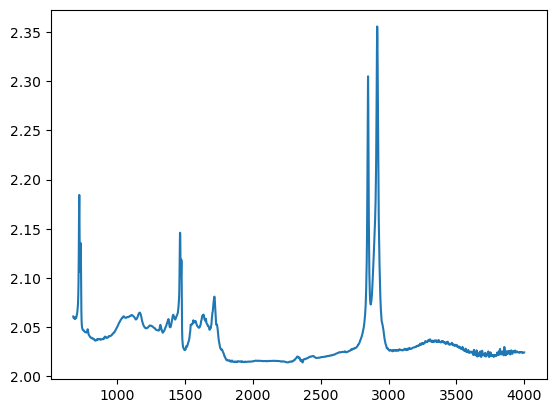

In [166]:
_ = plt.plot(df_list[0][0].iloc[:,:-3].T)

In [169]:
df_list[0][0]

wavenumber,674.9918,676.9203,678.8489,680.7775,682.706,684.6345,686.5631,688.4916,690.4202,692.3488,...,3988.237,3990.166,3992.094,3994.023,3995.951,3997.88,3999.809,polymer,map_x,map_y
PE38,2.060827,2.05951,2.059122,2.059101,2.059809,2.059586,2.058348,2.058331,2.059721,2.059846,...,2.023646,2.023848,2.02411,2.024125,2.024272,2.024396,2.024353,PE38,,


In [170]:
spectra.mean(1)[0]

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9712/1239458316.py:1: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  spectra.mean(1)[0]


2.038010445922247

In [171]:
args.si_peak = [520]*len(df_list)
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


In [172]:
raman_final.shape, ir_final.shape

((1, 1451), (1, 535))

In [175]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['id'] = ['PE38']#['iN10 stearate'] #'PE38',
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir.to_csv('gloves_contamination/data_match_new_PE38.csv')
preposs_data_ir

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2959.0,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,id,background
0,-0.382818,-0.373358,-0.363377,-0.348227,-0.336989,-0.3273,-0.311538,-0.297327,-0.284209,-0.269309,...,-0.283147,-0.323126,-0.369811,-0.423077,-0.474506,-0.523723,,,PE38,no_background


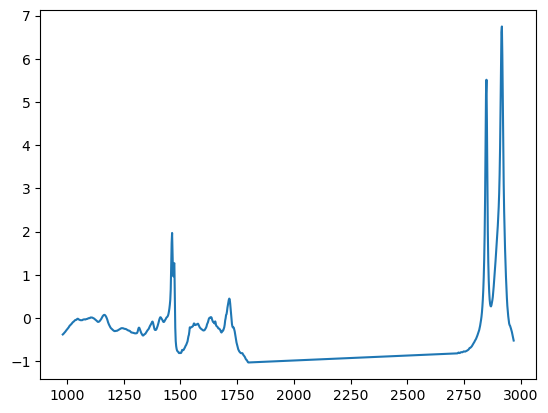

In [174]:
_ = plt.plot(preposs_data_ir.iloc[:,:-4].T)